# Part 2a: In comprehensive peace agreements, does it matter what role women hold?

Part 1 found that **comprehensive agreements** mention women far more often than other kinds. Part 2a looks inside those comprehensive agreements and asks about **power**: are gender provisions more likely when a woman **signs** the agreement, the role with formal decision power, than when women are only **present** (as negotiators, observers, mediators, advisers or in women's committees)?

| Dataset | What it gives us |
|---|---|
| **PA-X Peace Agreements Database v10** (University of Edinburgh) | The outcome, `GeWom` (does the agreement mention women, girls or gender?), plus year, region and UN involvement |
| **PADD: Peace Agreement Delegate Dataset 1.0** (Good, *American Political Science Review*, 2025) | Every person named in 116 comprehensive agreements (1990–2020), with their **role** and coded **gender** |

Both datasets use the same agreement ID (`AgtId`), so they join exactly, with no name matching.

**Plan**
1. Take every comprehensive agreement in PA-X from 1990–2020 (119) and join PADD
2. Understand how PADD decided gender
3. Which roles do women hold?
4. Compare agreements where a woman signed, where women were only present, and where no women were named
5. Hold the era constant with logistic regression
6. Robustness check: use only the most reliable gender coding
7. Conclusions and limitations

In [1]:
import numpy as np  # math
import pandas as pd  # tables
import matplotlib.pyplot as plt  # figures
import seaborn as sns  # statistical charts
import statsmodels.formula.api as smf  # logistic regression
sns.set_theme(style="whitegrid")  # chart style
pd.set_option("display.width", 160)  # wider printed tables

## 1. Comprehensive agreements in PA-X, joined to PADD

In [2]:
pax = pd.read_csv("gender-provisions-in-peace-agreements.csv", low_memory=False).copy()  # PA-X v10, 2,257 agreements
pax["gender"] = (pax["GeWom"] > 0).astype(int)  # outcome: any provision on women, girls or gender
pax["year"] = pd.to_datetime(pax["Dat"], errors="coerce").dt.year  # signing year
comp = pax[(pax["Stage"] == "SubComp") & (pax["year"] <= 2020)][["AgtId", "Agt", "Con", "Reg", "year", "ImUN", "gender"]]  # comprehensive, PADD's years
print("comprehensive agreements in PA-X, 1990-2020:", len(comp))  # 119

comprehensive agreements in PA-X, 1990-2020: 119


In [3]:
padd = pd.read_csv("padd-agreement-level.csv")  # PADD: one row per agreement (116)
delegates = pd.read_csv("padd-delegate-level.csv", low_memory=False)  # PADD: one row per named person (2,301)
print("PADD agreements:", len(padd), "| PADD delegate rows:", len(delegates))  # sizes

data = comp.merge(padd[["AgtId", "Del_N", "FemDel_N", "FemDel_P", "Sig_N", "FemSig_N", "FemSig_P"]], on="AgtId", how="left", indicator=True)  # keep all 119
data["padd_status"] = data["_merge"].map({"both": "In PADD", "left_only": "Not in PADD"})  # flag the gaps instead of dropping them
data = data.drop(columns="_merge")  # tidy
data["padd_status"].value_counts()  # 116 in PADD, 3 not

PADD agreements: 116 | PADD delegate rows: 2301


padd_status
In PADD        116
Not in PADD      3
Name: count, dtype: int64

In [4]:
data.loc[data["padd_status"] == "Not in PADD", ["AgtId", "year", "Con", "Agt"]]  # the 3 gaps

,AgtId,year,Con,Agt
28,2487,1996,Ghana,Kumasi Accord on Peace and Reconciliation Betw...
113,2683,2019,Sudan,Final Constitutional Charter for the 2019 Tran...
118,2679,2020,South Sudan,Resolutions Agreed Between Pakam and Rup Commu...


The 3 agreements without PADD data have high PA-X IDs (2487–2683): **PA-X added them after PADD was published in 2024**. They stay in the table, marked "Not in PADD", rather than being dropped silently.

## 2. How PADD decided each person's gender

PADD codes gender from **names**, not from asking people (the codebook calls it *assumed* gender):

1. Each name goes through **Gender API**, which returns male or female and a confidence score (0–100).
2. If every version of the name (full, first, middle) agrees and confidence is **above 75**, that answer is kept.
3. Otherwise the author **checked by hand** using social media, LinkedIn, employee profiles and news.
4. If it's still unclear, the software's guess is used; if nothing works, the person is **unknown**.

In [5]:
g = delegates[["cmb_ga_gender_given", "gvn_ga_gender", "mid_ga_gender"]]  # software answers for full, first, middle name
acc = delegates[["cmb_ga_accuracy_given", "gvn_ga_accuracy", "mid_ga_accuracy"]].apply(pd.to_numeric, errors="coerce")  # software confidence
named = delegates["Name"].notna() | delegates["Given_Name"].notna()  # people with a name in the text
answers = g.apply(lambda r: {v for v in r if v in ("male", "female")}, axis=1)  # distinct software answers per person
min_conf = acc.where(g.isin(["male", "female"]).values).min(axis=1)  # weakest confidence among the answers
delegates["software_confident"] = named & (answers.map(len) == 1) & (min_conf > 75)  # codebook rule for "software alone decides"
summary = pd.Series({"named people": int(named.sum()),
                     "decided by software alone": int(delegates["software_confident"].sum()),
                     "needed a hand check": int((named & ~delegates["software_confident"]).sum()),
                     "women (final)": int((delegates["FemTrack1"] == 1).sum()),
                     "men (final)": int((delegates["FemTrack1"] == 0).sum()),
                     "unknown (final)": int(delegates["FemTrack1"].isna().sum())})  # counts
summary  # about a quarter of named people needed a hand check

named people                 2071
decided by software alone    1590
needed a hand check           481
women (final)                 191
men (final)                  1801
unknown (final)               309
dtype: int64

## 3. Which roles do women hold?

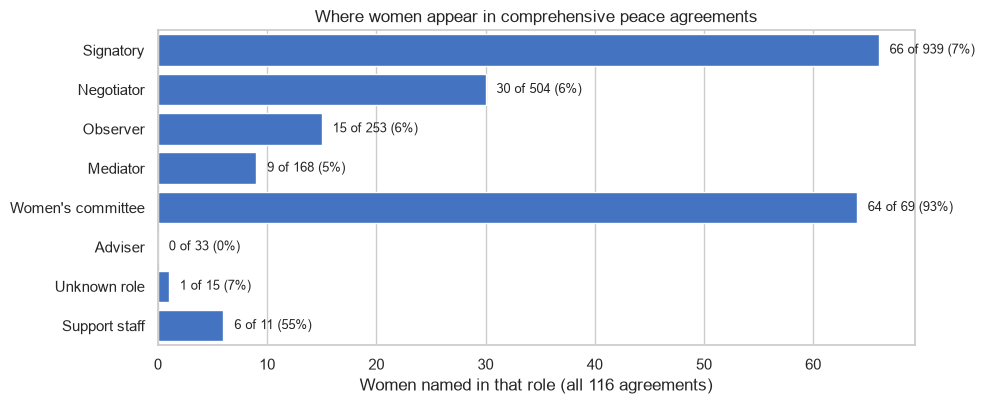

,people,women,share women
role,,,
Signatory,939,66.0,0.070
Negotiator,504,30.0,0.060
Observer,253,15.0,0.059
Mediator,168,9.0,0.054
Women's committee,69,64.0,0.928
Adviser,33,0.0,0.000
Unknown role,15,1.0,0.067
Support staff,11,6.0,0.545


In [6]:
ROLE = {"Sig": "Signatory", "Neg": "Negotiator", "Ob": "Observer", "Med": "Mediator", "Adv": "Adviser", "Log": "Support staff", "WomCom": "Women's committee", "Unknown": "Unknown role"}  # PADD role codes
known = delegates[delegates["FemTrack1"].notna() & delegates["Pos_Smp"].notna()].copy()  # people with a known gender and role
known["role"] = known["Pos_Smp"].map(ROLE)  # readable role
by_role = known.groupby("role")["FemTrack1"].agg(people="size", women="sum")  # people and women per role
by_role["share women"] = (by_role["women"] / by_role["people"]).round(3)  # women's share of each role
by_role = by_role.sort_values("people", ascending=False)  # biggest roles first

fig, ax = plt.subplots(figsize=(10, 4.2))  # one chart
order = by_role.index.tolist()  # same order as the table
sns.barplot(x=by_role["women"], y=order, ax=ax, color="#2f6fd6")  # women per role
for i, (r, row) in enumerate(by_role.iterrows()):  # label each bar
    ax.text(row["women"] + 1, i, f"{int(row['women'])} of {int(row['people'])} ({row['share women']:.0%})", va="center", fontsize=9)  # count and share
ax.set(xlabel="Women named in that role (all 116 agreements)", ylabel="", title="Where women appear in comprehensive peace agreements")  # labels
plt.tight_layout(); plt.show()  # draw
by_role  # numbers behind the chart

Women are only **7% of signatories** (66 of 939 with a known gender) and 6% of negotiators. Most of their remaining appearances are in **women's committees**, separate bodies that the UN calls "track 1.5" rather than the main table.

## 4. Did a woman sign, or were women only present?

Each agreement goes into one of three groups:
- **Woman signatory**: at least one woman signed.
- **Women present, none signed**: women were named in other roles only.
- **No women named**: no woman appears in the agreement text.

In [7]:
women_roles = delegates[delegates["FemTrack1"] == 1].groupby("AgtId")["Pos_Smp"].agg(set)  # roles held by women in each agreement

def role_group(row, roles=women_roles):  # classify one agreement
    if row["padd_status"] == "Not in PADD":  # no PADD data
        return "Not in PADD"  # keep the gap visible
    held = roles.get(row["AgtId"], set())  # women's roles in this agreement
    if "Sig" in held:  # at least one woman signed
        return "Woman signatory"  # decision power
    return "Women present, none signed" if held else "No women named"  # present only, or nobody

data["role_group"] = data.apply(role_group, axis=1)  # add the group
data["post2000"] = (data["year"] > 2000).astype(int)  # after UN Resolution 1325
data.to_csv("women-signatories-rebuilt.csv", index=False)  # save the joined table (119 rows)

def wilson(k, n, z=1.96):  # 95% interval for a share
    p = k / n; d = 1 + z**2 / n  # share and denominator
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d  # center and half-width
    return c - h, c + h  # (low, high)

ORDER = ["Woman signatory", "Women present, none signed", "No women named"]  # display order
tab = data[data["padd_status"] == "In PADD"].groupby("role_group")["gender"].agg(yes="sum", n="size").reindex(ORDER)  # counts per group
tab["share"] = tab["yes"] / tab["n"]  # share that mention women
tab[["lo", "hi"]] = [wilson(k, n) for k, n in zip(tab["yes"], tab["n"])]  # interval per group
tab.round(2)  # 80% vs 61% vs 53%

,yes,n,share,lo,hi
role_group,,,,,
Woman signatory,16,20,0.80,0.58,0.92
"Women present, none signed",11,18,0.61,0.39,0.80
No women named,41,78,0.53,0.42,0.63


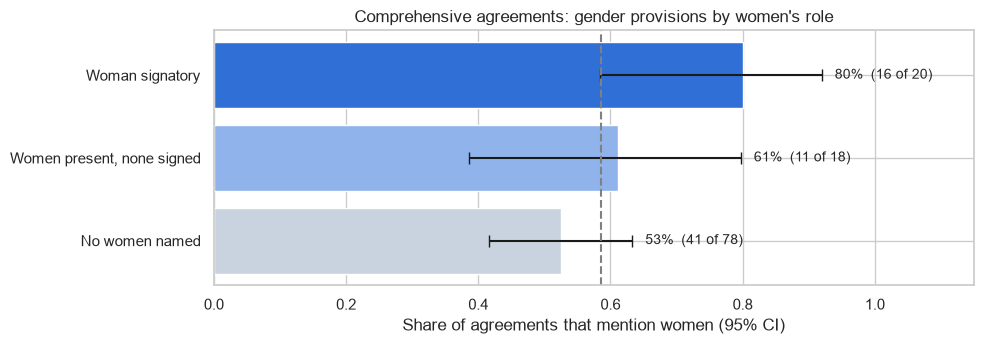

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.6))  # one chart
colors = ["#2f6fd6", "#8fb3ea", "#c9d3df"]  # strongest role = darkest
ax.barh(range(3), tab["share"], color=colors, xerr=[tab["share"] - tab["lo"], tab["hi"] - tab["share"]], capsize=4)  # bars with 95% intervals
ax.set_yticks(range(3)); ax.set_yticklabels(ORDER); ax.invert_yaxis()  # group names top to bottom
for i, r in enumerate(tab.itertuples()):  # label each bar
    ax.text(r.hi + 0.02, i, f"{r.share:.0%}  ({r.yes} of {r.n})", va="center", fontsize=10)  # share and counts
ax.axvline(data.loc[data.padd_status == "In PADD", "gender"].mean(), ls="--", c="gray")  # all 116 agreements
ax.set(xlim=(0, 1.15), xlabel="Share of agreements that mention women (95% CI)", title="Comprehensive agreements: gender provisions by women's role")  # labels
plt.tight_layout(); plt.show()  # draw

When a woman **signed**, 80% of agreements mention women. When women were **present but none signed**, 61%, barely above the 53% for agreements with **no women named**. The intervals overlap because the groups are small, so the next step holds the era constant.

## 5. Holding the era constant

Agreements after 2000 (UN Resolution 1325) mention women more often **and** have more women signatories, so the era could explain the difference. The regression compares each group with "No women named", with and without that control.

In [9]:
pp = data[data["padd_status"] == "In PADD"].copy()  # the 116 with PADD data
pp["woman_signed"] = (pp["role_group"] == "Woman signatory").astype(int)  # group dummies
pp["present_only"] = (pp["role_group"] == "Women present, none signed").astype(int)  # (reference = no women named)
rows = []  # one row per model
for formula in ["gender ~ woman_signed + present_only", "gender ~ woman_signed + present_only + post2000"]:  # without / with the era
    m = smf.logit(formula, pp).fit(disp=0)  # fit
    ci = np.exp(m.conf_int())  # 95% intervals as odds ratios
    for term in ["woman_signed", "present_only", "post2000"]:  # report each term
        if term in m.params:  # only terms in this model
            rows.append([formula.replace("gender ~ ", ""), term, round(np.exp(m.params[term]), 2), f"{ci.loc[term, 0]:.2f} to {ci.loc[term, 1]:.2f}", round(m.pvalues[term], 3)])  # OR, CI, p
pd.DataFrame(rows, columns=["model", "term", "odds ratio", "95% CI", "p"])  # results

,model,term,odds ratio,95% CI,p
0,woman_signed + present_only,woman_signed,3.61,1.11 to 11.78,0.033
1,woman_signed + present_only,present_only,1.42,0.50 to 4.04,0.513
2,woman_signed + present_only + post2000,woman_signed,3.34,1.01 to 11.11,0.049
3,woman_signed + present_only + post2000,present_only,1.37,0.47 to 4.01,0.560
4,woman_signed + present_only + post2000,post2000,2.42,1.09 to 5.36,0.030


- **A woman signatory**: about **3.3×** the odds of a gender provision, even with the era held constant (p ≈ 0.05).
- **Women present but not signing**: about 1.4×, and not distinguishable from no women at all (p ≈ 0.56).

Presence alone doesn't move the needle; holding the pen does. This matches the PADD paper's "power over presence" finding.

In [10]:
rows = []  # shares as continuous measures, per +10 percentage points
for col in ["FemDel_P", "FemSig_P"]:  # women's share of all delegates / of signatories
    part = pp.dropna(subset=[col])  # rows with that measure
    m = smf.logit(f"gender ~ {col} + post2000", part).fit(disp=0)  # with the era
    lo, hi = m.conf_int().loc[col]  # interval on the log-odds scale
    rows.append([{"FemDel_P": "% women among all named delegates", "FemSig_P": "% women among signatories"}[col], len(part), round(np.exp(0.1 * m.params[col]), 2), f"{np.exp(0.1 * lo):.2f} to {np.exp(0.1 * hi):.2f}", round(m.pvalues[col], 3)])  # OR per +10 points
pd.DataFrame(rows, columns=["measure", "agreements", "OR per +10 pts", "95% CI", "p"])  # both point the same way

,measure,agreements,OR per +10 pts,95% CI,p
0,% women among all named delegates,108,2.68,1.20 to 5.96,0.016
1,% women among signatories,103,3.18,1.03 to 9.85,0.044


## 6. Robustness check: only the most reliable gender coding

About a quarter of named people needed a hand check. If the finding depended on uncertain coding, it would weaken when we keep only people whose gender the software decided **confidently** (all names agree, confidence > 75).

In [11]:
strict_roles = delegates[(delegates["FemTrack1"] == 1) & delegates["software_confident"]].groupby("AgtId")["Pos_Smp"].agg(set)  # women, confident coding only
pp["role_strict"] = pp.apply(lambda r: role_group(r, strict_roles), axis=1)  # regroup with the strict list
pp["woman_signed_strict"] = (pp["role_strict"] == "Woman signatory").astype(int)  # strict dummies
pp["present_only_strict"] = (pp["role_strict"] == "Women present, none signed").astype(int)
print(pp.groupby("role_strict")["gender"].agg(["sum", "size", "mean"]).reindex(ORDER).round(2))  # shares under strict coding
m = smf.logit("gender ~ woman_signed_strict + present_only_strict + post2000", pp).fit(disp=0)  # same model
print("woman signatory OR (strict):", round(np.exp(m.params["woman_signed_strict"]), 2), "| p =", round(m.pvalues["woman_signed_strict"], 3))  # compare with 3.3

                            sum  size  mean
role_strict                                
Woman signatory              13    14  0.93
Women present, none signed   10    16  0.62
No women named               45    86  0.52
woman signatory OR (strict): 13.13 | p = 0.017


With only confidently coded people, 13 of 14 agreements with a woman signatory mention women, and the odds ratio rises (with a very wide interval, since only one of those 14 doesn't mention women). The direction holds, so uncertain coding isn't creating the result.

## 7. Over time

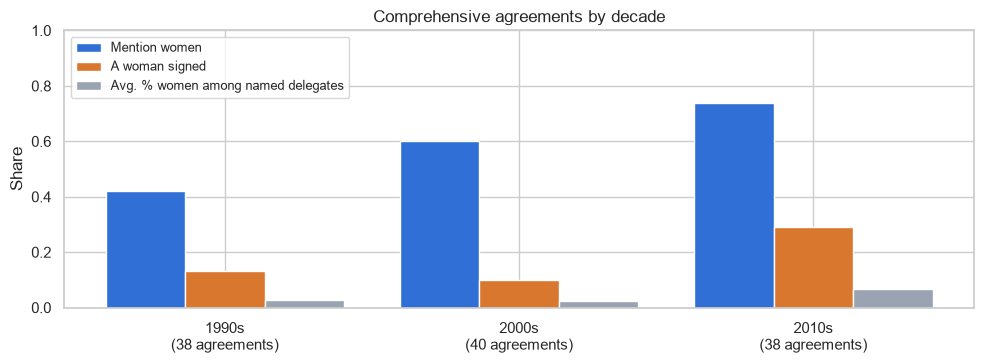

,agreements,woman_signed,women_delegates,mention_women
decade,,,,
1990s,38,0.132,0.027,0.421
2000s,40,0.100,0.024,0.600
2010s,38,0.289,0.067,0.737


In [12]:
pp["decade"] = pd.cut(pp["year"], [1989, 1999, 2009, 2020], labels=["1990s", "2000s", "2010s"])  # three periods
trend = pp.groupby("decade", observed=True).agg(agreements=("AgtId", "size"), woman_signed=("woman_signed", "mean"), women_delegates=("FemDel_P", "mean"), mention_women=("gender", "mean"))  # per period
fig, ax = plt.subplots(figsize=(10, 3.8))  # one chart
x = np.arange(len(trend)); wdt = 0.27  # bar positions
ax.bar(x - wdt, trend["mention_women"], wdt, label="Mention women", color="#2f6fd6")  # outcome
ax.bar(x, trend["woman_signed"], wdt, label="A woman signed", color="#d9772f")  # women signatories
ax.bar(x + wdt, trend["women_delegates"], wdt, label="Avg. % women among named delegates", color="#9aa3b2")  # women's share
ax.set_xticks(x); ax.set_xticklabels([f"{d}\n({n} agreements)" for d, n in zip(trend.index, trend["agreements"])])  # labels
ax.set(ylim=(0, 1), ylabel="Share", title="Comprehensive agreements by decade"); ax.legend(fontsize=9, loc="upper left")  # labels
plt.tight_layout(); plt.show()  # draw
trend.round(3)  # numbers behind the chart

Women signatories became more common in the 2010s (29% of agreements vs. about 10–13% before), but women remain a small share of everyone named (under 7% on average).

## 8. Conclusions and limitations

**Answer.** In comprehensive peace agreements, **what role women hold matters**. Agreements where a woman signed mention women 80% of the time, with about **3× the odds**, even holding the era constant. Women present without signing make no clear difference compared with no women at all.

**Robustness.** Counting only people whose gender the software coded confidently, the gap gets *wider*: 13 of 14 agreements with a woman signatory mention women (93%), vs. 52% with no women named. Uncertain gender coding isn't creating the result.

**Limitations**
- **Assumed gender.** PADD infers gender from names, with hand checks for uncertain cases; 309 people (13%) are unknown.
- **Only people named in the text.** Women in a delegation who aren't listed in the signed document are invisible to PADD.
- **Comprehensive agreements only.** Stage, the strongest predictor in part 1, can't be compared here; part 2b covers other stages with CFR.
- **Small groups.** Only 20 agreements have a woman signatory, so the intervals are wide.
- **Association, not cause.** Processes that let women sign may already be committed to gender issues.
- **Coverage.** 3 of the 119 comprehensive agreements were added to PA-X after PADD and have no PADD data.